# A6_v4: the JAISP photometry head — what it achieves, how it works, what is left

**A6_v4** is a deep-learning photometry head on the frozen JAISP foundation: it predicts non-parametric shapes (and a centroid correction) for every detected source in a scene, and the fluxes of all sources are then solved jointly from the pixels. It was selected on injections with known truth and is evaluated here on real held-out tiles against MER, the mixture photometer, Tractor and aperture photometry.

**Headline results** (details and definitions in the sections below):
- **Bright isolated galaxies** (MER VIS < 22.5, nothing within 3″): A6 agrees with MER to **0.049 mag** over VIS/Y/J/H (mixture 0.060, Tractor 0.059), with 88 % of measurements within 0.1 mag of MER.
- **Against MER over all 504 held-out sources**, A6 is the best or joint-best method in VIS and Y, within 0.01–0.02 mag of the mixture in J/H, and ahead of Tractor in every band. Solving the six pairwise scatters among A6, mixture, Tractor and MER gives each method's *own* scatter: **A6 0.080 = mixture 0.080**, Tractor ~0.15, MER ~0.10 mag. Most of any "vs MER" number is MER's own noise.
- **On injections with known truth** A6 beats the mixture everywhere: 8 % lower error overall, 14 % lower in close blends (< 0.7″), 13 % lower for bright sources, and it is robust to realistic centroid errors (the mixture and the previous head were not).
- **Deblending** is where it is clearly best: on real data its close-pair scatter against MER is 0.17 vs 0.18 (mixture) and 0.27 (Tractor).
- **Two follow-up heads were trained from A6_v4 and are evaluated here too** (section 6b): A8 (bright-source shape term, five trained passes) halves the bright-galaxy core residuals and improves the bright and faint ends on injections, but is not better than A6 on the real tiles; A7 (learned point-source template) changes nothing measurable. A6_v4 therefore remains the reference head.
- **Speed**: 0.33 s per measured source on one GPU vs 0.87 s per source per CPU core for Tractor, with an order of magnitude still available from batching.

Held-out tiles = the 8 validation tiles of `runs/truth_scarlet/split.json`, never used to train any head. The 28 detection-catalog test tiles, the 128-blend benchmark and the empirical injection pilot stay frozen. Code: `models/photometry/self_supervised/truth_scarlet/` (`model.py`, `train.py`, `scenes*.py`, `report_a6.py`); products under `runs/truth_scarlet/`; `python -m ...truth_scarlet.report_a6 precompute` regenerates the aperture photometry and example cutouts.

In [1]:
import sys, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd().resolve(); ROOT = ROOT if (ROOT / 'models').exists() else ROOT.parent
sys.path.insert(0, str(ROOT))
from models.photometry.self_supervised.truth_scarlet import report_a6 as R
from models.photometry.self_supervised.truth_scarlet.scenes import OUT as D
import torch
ck = torch.load(D / 'runs/A6_v4/best.pt', map_location='cpu', weights_only=False)
print('checkpoint:', D / 'runs/A6_v4/best.pt'); print('selected at', ck['seen'], 'training scenes; metadata:', {k: v for k, v in ck['metadata'].items() if k != 'foundation'})
print('head parameters:', sum(v.numel() for v in ck['head'].values()))

checkpoint: /home/shemmati/Work/Projects/JAISP/models/photometry/self_supervised/runs/truth_scarlet/runs/A6_v4/best.pt
selected at 72000 training scenes; metadata: {'width': 64, 'steps': 3, 'head': 'truth_v1', 'fixed_background': True, 'per_band': True, 'implicit_psf': False, 'use_foundation': True, 'perturbation': 2.0, 'eps_bound': 1.0, 'centroid': True}
head parameters: 483272


## 1. How it works
Five stages, left to right in the figure. Only stage 3 is trained.
1. **Scene**: a 12″ cutout in all ten bands with every detection inside it (up to 40), their PSFs, variances and masks.
2. **Features**: the frozen foundation encoder's fused 10-band bottleneck and its VIS stem, plus raw pixel windows, around each source.
3. **Shape network**: for each source, a CNN predicts an elliptical radial profile, a free-form modulation on top of it (up to 7×, so arms, bars and clumps can be represented), a per-band size and colour mix, and a centroid correction (≤ 0.2″). The residual of the current fit is fed back three times to refine these. The number of passes matters: running the trained head with 1, 2, 3, 4, 5 or 6 passes at inference on 400 validation scenes gives an overall error of 2.57, 2.45, **2.03**, 2.28, 2.12, 2.38 (bright sources: 5.9, 7.2, **4.5**, 7.4, 4.9, 7.3), i.e. each pass the net was trained for helps a lot (2 → 3 passes: 17 % overall, 37 % on bright sources, 14 % in close blends) and passes it was not trained for make it oscillate. Training with more passes is the obvious next experiment.
4. **Render**: each shape is convolved with each band's PSF at the corrected position, giving a unit-flux template per source and band.
5. **Flux solve**: the fluxes of all sources are solved jointly per band by weighted linear least squares with a fixed robust sky. The network never outputs a flux: fluxes are linear in the pixels and come with covariances.

The inference path is the amortised prediction with its trained refinement passes; fluxes are solved once per band at the end. (Refining the shapes further against the scene's own pixels at inference was tested and rejected: see "Does per-scene optimisation keep the fluxes right?" in section 4.)

The model is "amortised scarlet": scarlet's forward model (positive shapes × PSFs, joint linear fluxes) with the shapes predicted by a network instead of optimised per scene.

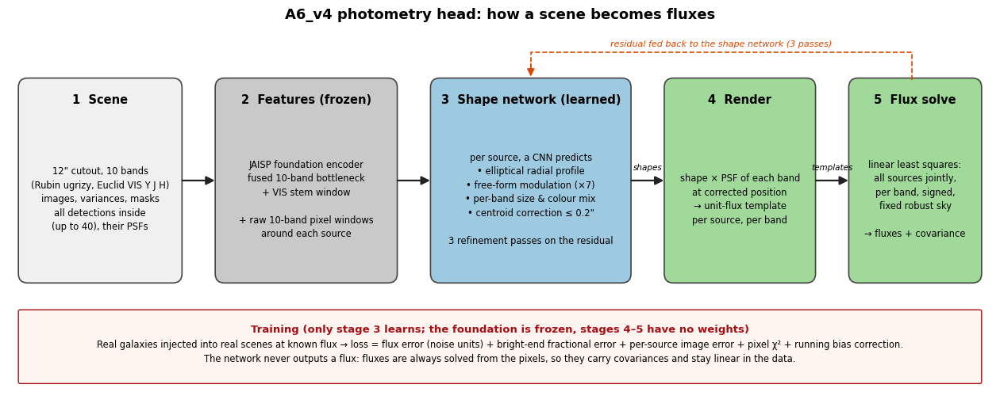

In [2]:
fig = R.fig_architecture(); plt.show()

### What the fitted shapes look like
Each source's shape is an elliptical monotone profile times a free-form modulation map (bounded to a factor ~7), so the network can represent elongation, asymmetry, bars and clumps rather than only ellipses. The gallery shows, for 25 held-out sources spanning VIS 19–26, the VIS data, the PSF-convolved model of that source after the gated per-scene optimisation in the same units and stretch (this is what enters the flux solve), and the intrinsic shape before the PSF at a much deeper stretch. Model and data agree panel by panel; the brightest galaxy's spiral structure is in the model, intermediate sources get their elongated and asymmetric shapes, and faint sources (below the 10σ gate, so carrying the network's shapes) are compact.

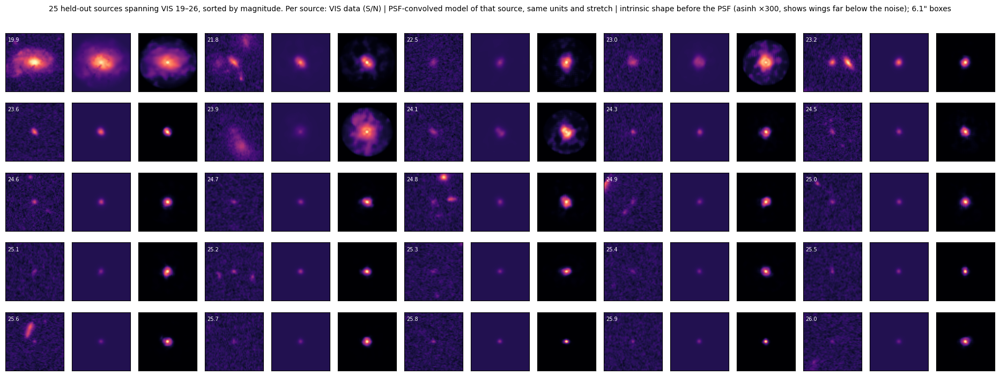

In [3]:
fig = R.fig_shapes(); plt.show()

### Loss (training only)
For injected sources with known truth $f^*$, template $M^*$ and oracle error $\sigma$ (the error of a fit with the true template):

$\mathcal{L} = \mathrm{Huber}\big((f-f^*)/\sigma\big) + \mathrm{Huber}\big(20\,(f-f^*)/f^*\big)_{S/N>10} + \big\| (f\hat T - f^* M^*\otimes\mathrm{PSF})/\sigma_{\rm pix}\big\|^2 / \|f^* M^*\otimes\mathrm{PSF}/\sigma_{\rm pix}\|^2 + 0.1\,\overline{\log\chi^2/\mathrm{dof}} + \sum_{\rm S/N\,bin,\,band} \mathrm{EMA}\cdot\overline{\chi}$

The first term handles the faint end in noise units, the second makes bright-end fractional accuracy count (the χ term saturates for bright sources), the third penalises light trading between blended sources even when totals are right, the χ² term keeps every pixel explained (including real neighbours without truth), and the last is a running-mean dual-ascent correction that drives the mean signed error in each (S/N bin, band) cell to zero. Real detections in the training scenes are fitted jointly but carry no truth; injected positions are jittered by the real centroid-error distribution.

## 2. Training data (v4)
20 000 scenes: 75 % inject real galaxies into real 12″ cutouts from 105 training tiles (all real detections fitted alongside), 25 % onto blank sky. Donors: 4 375 real galaxies (nonparametric reconstructions for S/N ≥ 8, Sérsic profiles from MER structural parameters for S/N 3–8, 168 point-like), each injected near its own brightness so the size–brightness relation of the injected population matches the real sky; random intrinsic rotation/flip; 30 % of primaries are bright extended galaxies. Galleries are under `runs/truth_scarlet/train_v4/gallery/` (galleries below).

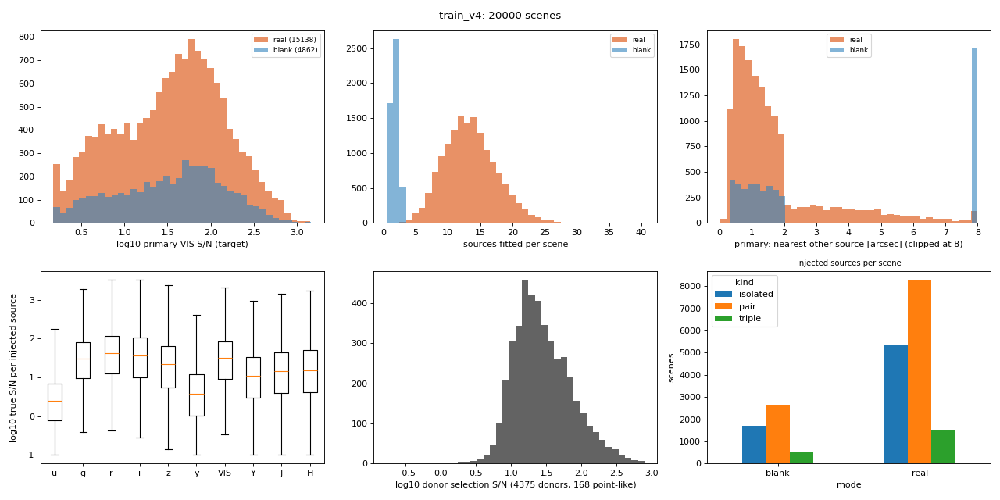

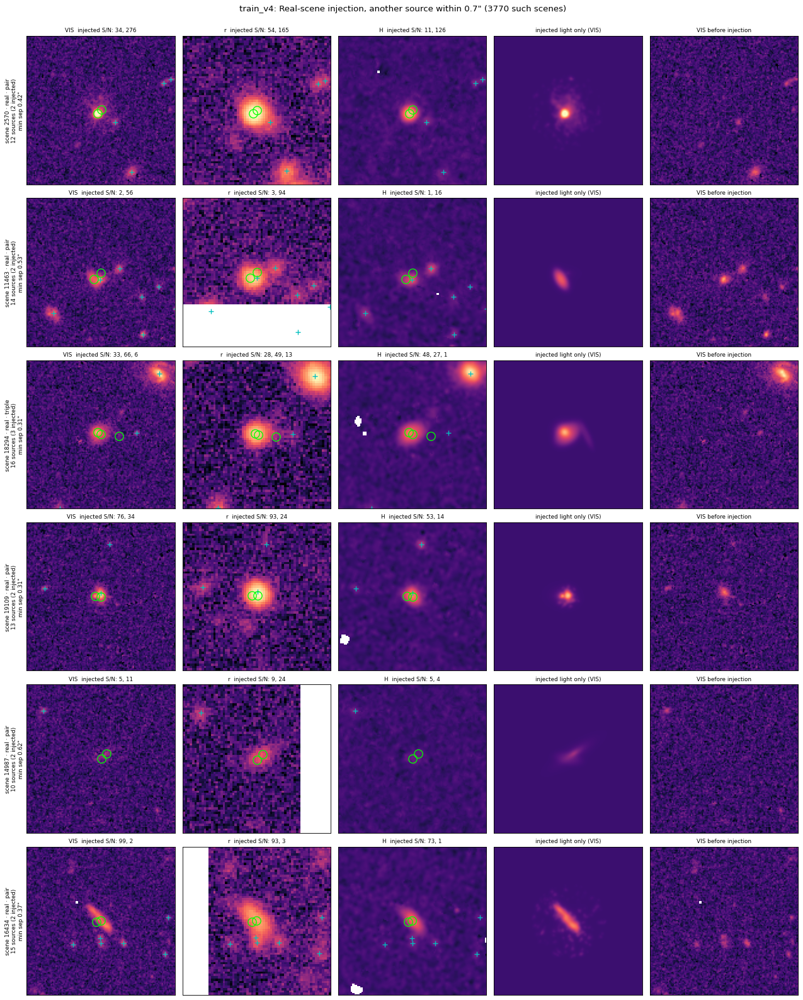

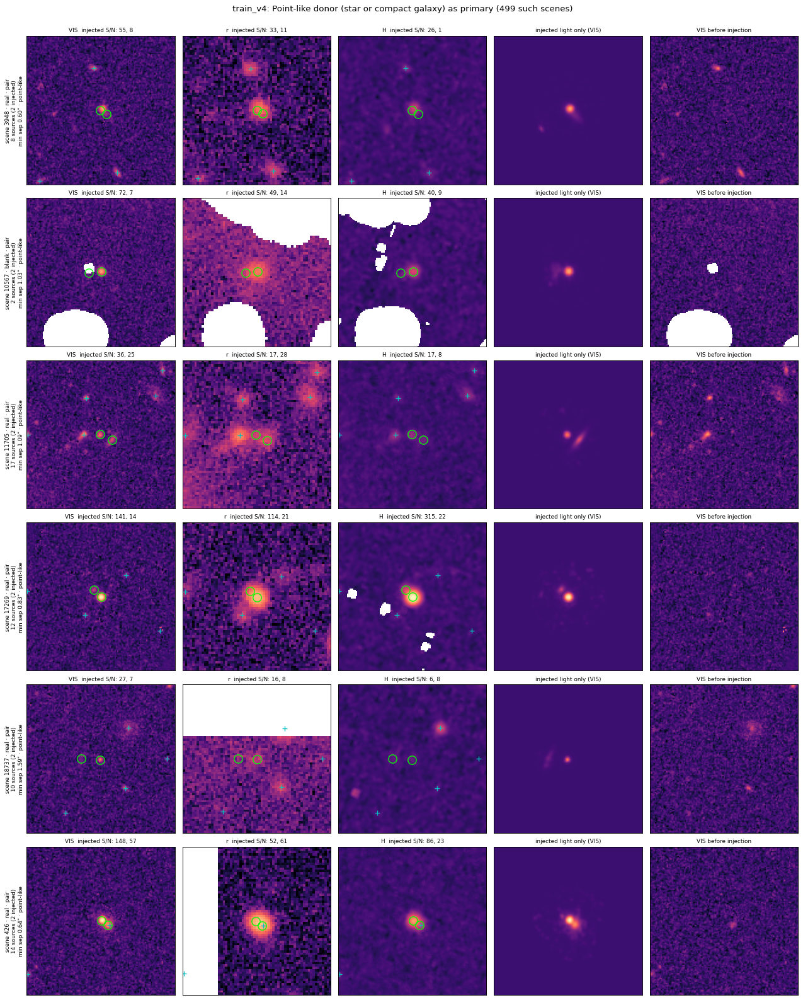

In [4]:
from IPython.display import Image, display
for name in ('00_distributions', '02_real_close_blend', '06_point_like'):
    p = D / 'train_v4/gallery' / f'{name}.png'
    if p.exists(): display(Image(filename=str(p), width=1500))

In [5]:
q = pd.read_csv(D / 'train_v4/donor_quality.csv'); q = q[q.suitable_v2]
from models.photometry.self_supervised.truth_scarlet.scenes import tile_dir, regions_of, extra_regions
real = pd.concat([pd.read_csv(tile_dir(r) / 'mer_match.csv') for r in regions_of('train') + extra_regions()]); real = real[real.matched & (real.mer_flux_vis_sersic > 0)]
rmag = 23.9 - 2.5 * np.log10(real.mer_flux_vis_sersic); edges = [18, 22, 23, 24, 25, 26, 28]
rows = [dict(vis_mag=f'{a}-{b}', donors=int(q.vis_mag.between(a, b).sum()), donor_r50_arcsec=round(float(q.r50_arcsec[q.vis_mag.between(a, b)].median()), 3), MER_sersic_radius_arcsec=round(float(real.mer_sersic_sersic_vis_radius[rmag.between(a, b)].median()), 3)) for a, b in zip(edges[:-1], edges[1:])]
print('Size-brightness check: training donors vs real detections'); pd.DataFrame(rows)

Size-brightness check: training donors vs real detections


,vis_mag,donors,donor_r50_arcsec,MER_sersic_radius_arcsec
0,18-22,433,0.556,0.690
1,22-23,635,0.432,0.533
2,23-24,963,0.374,0.425
3,24-25,1611,0.361,0.338
4,25-26,641,0.224,0.210
5,26-28,91,0.200,0.123


## 3. Training: the lineage, and the last fine-tune
A6_v4 is the end of a chain of fine-tunes, each starting from the previous head and changing one thing (loss, data version, shape freedom, centroid). Most of the progress happened along that chain; the figure below shows every head's best checkpoint on the same real held-out tiles (all comparable) and, for the heads validated on `val_v3`, on injections. The last two entries, A7 and A8, are the follow-ups discussed in section 6b; both start from A6_v4.

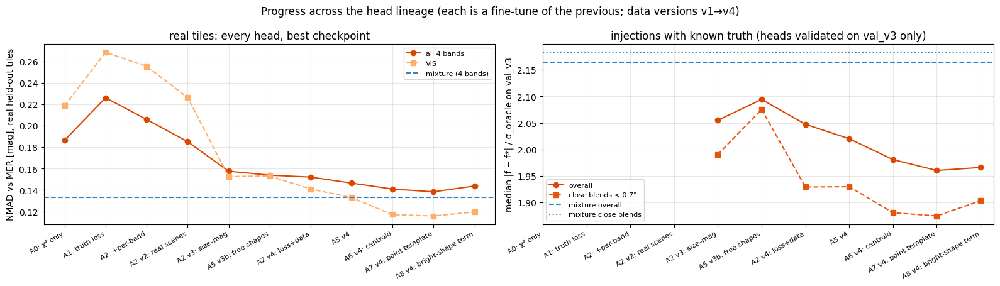

,run,label,real_nmad,real_vis,val_v3,close_v3
0,A0,A0: χ² only,0.186,0.219,NaN,NaN
1,A1,A1: truth loss,0.226,0.268,NaN,NaN
2,A2,A2: +per-band,0.206,0.255,NaN,NaN
3,A2_v2,A2 v2: real scenes,0.185,0.226,NaN,NaN
4,A2_v3,A2 v3: size–mag,0.158,0.153,2.055,1.991
5,A5_v3b,A5 v3b: free shapes,0.154,0.153,2.094,2.075
6,A2_v4,A2 v4: loss+data,0.152,0.141,2.047,1.929
7,A5_v4,A5 v4,0.146,0.133,2.020,1.930
8,A6_v4,A6 v4: centroid,0.141,0.117,1.981,1.881
9,A7_v4,A7 v4: point template,0.138,0.116,1.960,1.874


In [6]:
fig = R.fig_lineage(); plt.show(); R.lineage_table().round(3)

Reading the left panel: over the four Euclid bands A6 ends at 0.141 vs the mixture's 0.133 against MER, with VIS already below the mixture (0.117 vs 0.121). The remaining 4-band difference is entirely J and H (0.137 vs 0.125 and 0.150 vs 0.128). Two independent measurements say this is not A6 being noisier in those bands: the four-way scatter decomposition in section 5 gives the same own scatter for both methods in H (0.075 vs 0.077), and on injections with known truth A6 is clearly better than the mixture in both bands (J 1.30 vs 1.54, H 1.46 vs 1.66, section 4). What differs is the relation to MER: MER's NISP fluxes are template fits that impose the VIS shape on the NISP bands, and the mixture's prior is VIS-first in the same spirit, so the two make correlated errors; A6 fits the NISP shapes per band. Agreement with MER in J/H therefore partly rewards sharing MER's modelling choices.

The last step, A6_v4 itself, was fine-tuned from A5_v4 for 5 epochs (100k scenes) at a low learning rate; its own validation curve moves by a few per cent (real-tile NMAD 0.147 → 0.140, injections 2.02 → 1.98) around a checkpoint-to-checkpoint noise of ±0.02, so it is not shown. Validation ran every 8 000 scenes on `val_v3` and on the 504 real sources; the checkpoint (72k scenes) was selected on the injection metric only. Its faint-end bias (−10 % at S/N < 3 on injections) is a property of the scenes rather than of training: the oracle with the true shapes and a free background shows −17 % on the same scenes, because faint undetected light couples into any constant-background fit; the running-mean correction in the loss drives the clipped *mean* error per S/N bin and band to zero, which is a different statistic from this median.

## 4. Validation on injections with known truth (`val_v3`)
Held-out real galaxies injected into held-out real scenes (and blank sky), so every injected flux and profile is known exactly. The *oracle* is a linear fit with the true templates and a free constant background: the best any method could do given the sky. Errors are in units of the oracle error σ.

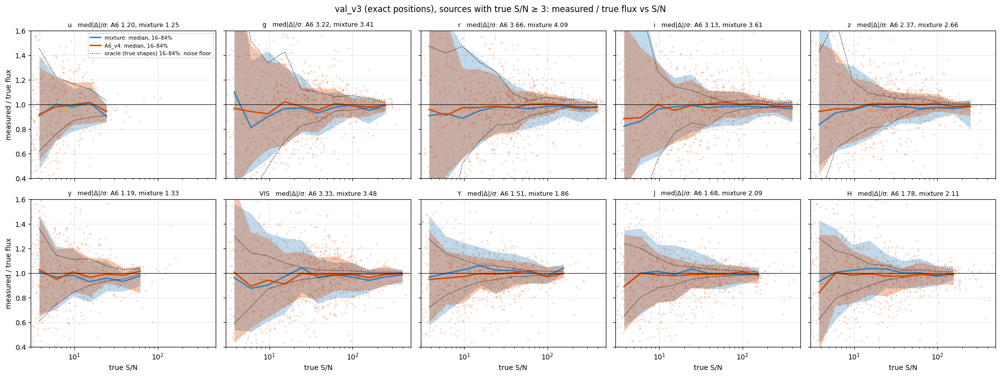

In [7]:
exact = R.injection_table('val_v3'); fig = R.fig_flux_scatter(exact, title='val_v3 (exact positions), sources with true S/N ≥ 3: measured / true flux vs S/N'); plt.show()

The bands are the 16–84 % range of measured/true flux; the dotted lines are the same range for the oracle that knows the true shapes, i.e. the photon-noise floor. At S/N 3–10 that floor is already ±20–30 %, so the width there is noise, not model error; A6's band sits inside the mixture's at every S/N and approaches the floor at the faint end. The figure below compares the scatter with the floor directly.

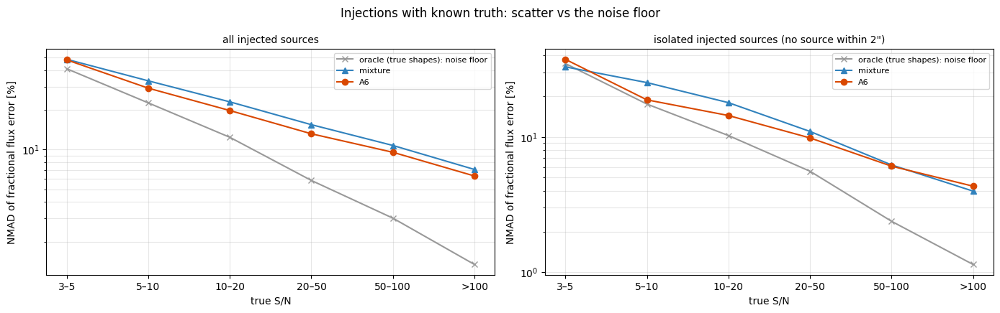

Fractional scatter (NMAD, %) by true S/N: at the faint end A6 is within 20-30% of the noise floor; at the bright end it is method-limited (headroom)


,oracle_pct,A6_pct,A6_over_floor,mixture_pct,mixture_over_floor
snr,,,,,
3-5,41.2,48.1,1.17,48.6,1.18
5-10,22.7,29.3,1.29,33.4,1.47
10-20,12.4,19.8,1.60,23.1,1.86
20-50,5.8,13.2,2.26,15.5,2.65
50-100,3.0,9.5,3.17,10.8,3.57
100-inf,1.3,6.3,4.71,7.1,5.28


In [8]:
fig = R.fig_vs_floor(exact); plt.show()
floor = []
for lo, hi in [(3, 5), (5, 10), (10, 20), (20, 50), (50, 100), (100, 1e9)]:
    o, a, m = (exact[k] for k in ('oracle', 'A6', 'mixture')); so, sa, sm = ((f.true_snr >= lo) & (f.true_snr < hi) for f in (o, a, m))
    floor.append(dict(snr=f'{lo}-{hi if hi < 1e9 else "inf"}', oracle_pct=round(100 * R.nmad(o.frac[so]), 1), A6_pct=round(100 * R.nmad(a.frac[sa]), 1), A6_over_floor=round(R.nmad(a.frac[sa]) / R.nmad(o.frac[so]), 2), mixture_pct=round(100 * R.nmad(m.frac[sm]), 1), mixture_over_floor=round(R.nmad(m.frac[sm]) / R.nmad(o.frac[so]), 2)))
print('Fractional scatter (NMAD, %) by true S/N: at the faint end A6 is within 20-30% of the noise floor; at the bright end it is method-limited (headroom)'); pd.DataFrame(floor).set_index('snr')

In [9]:
def summary(runs):
    rows = []
    for k, f in runs.items():
        perband = np.mean([np.median(np.abs(f.chi[f.band == b])) for b in f.band.unique()])
        rows.append(dict(method=k, overall=perband, **{c: np.median(np.abs(f.chi[f.context == c])) for c in ('isolated', 'blend 0.7-2"', 'blend <0.7"')},
                         bright_snr30=np.median(np.abs(f.chi[f.true_snr > 30])), bias_snr_lt3=np.median(f.frac[f.true_snr < 3]), bias_snr_3_10=np.median(f.frac[(f.true_snr >= 3) & (f.true_snr < 10)]),
                         frac_nmad_snr30=R.nmad(f.frac[f.true_snr > 30])))
    return pd.DataFrame(rows).set_index('method').round(3)
print('val_v3, exact positions (median |Δ|/σ; bias = median fractional error)'); display(summary(exact))
jit = R.injection_table('val_v3_jit'); print('val_v3_jit: injected positions perturbed by the real centroid-error distribution'); display(summary(jit))

val_v3, exact positions (median |Δ|/σ; bias = median fractional error)


,overall,isolated,"blend 0.7-2""","blend <0.7""",bright_snr30,bias_snr_lt3,bias_snr_3_10,frac_nmad_snr30
method,,,,,,,,
oracle,1.426,1.010,1.190,1.266,1.442,-0.168,-0.042,0.030
mixture,2.164,1.524,1.839,2.183,5.073,0.045,-0.043,0.103
A6,1.980,1.434,1.693,1.881,4.440,-0.132,-0.039,0.091


val_v3_jit: injected positions perturbed by the real centroid-error distribution


,overall,isolated,"blend 0.7-2""","blend <0.7""",bright_snr30,bias_snr_lt3,bias_snr_3_10,frac_nmad_snr30
method,,,,,,,,
oracle,1.426,1.010,1.190,1.266,1.442,-0.168,-0.042,0.030
mixture,2.341,1.545,1.975,2.386,5.639,0.047,-0.047,0.115
A6,2.128,1.438,1.764,2.140,5.006,-0.143,-0.048,0.102


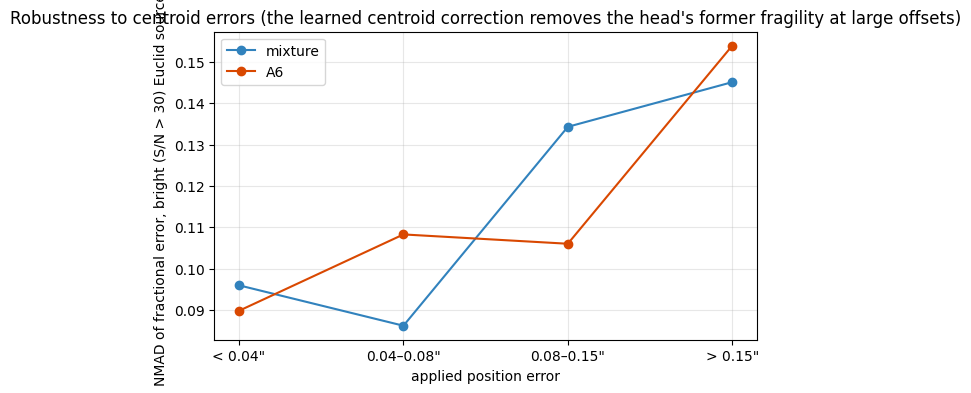

In [10]:
j = pd.read_csv(D / 'val_v3_jit/jitter.csv'); j['name'] = j.scene.map(lambda s: f'scene_{s:05d}')
fig, ax = plt.subplots(figsize=(7, 4))
for k, col in (('mixture', R.COL['mixture']), ('A6', R.COL['A6'])):
    f = jit[k].merge(j, on=['name', 'source']); f = f[(f.true_snr > 30) & f.band.str.startswith('euclid') & (f.source == 0)]
    bins = pd.cut(f.offset_arcsec, [-.001, .04, .08, .15, 1.]); ax.plot(range(4), [R.nmad(f.frac[bins == c]) for c in bins.cat.categories], 'o-', c=col, label=k)
ax.set_xticks(range(4)); ax.set_xticklabels(['< 0.04"', '0.04–0.08"', '0.08–0.15"', '> 0.15"']); ax.set_xlabel('applied position error'); ax.set_ylabel('NMAD of fractional error, bright (S/N > 30) Euclid sources'); ax.legend(); ax.grid(alpha=.3)
ax.set_title('Robustness to centroid errors (the learned centroid correction removes the head\'s former fragility at large offsets)'); plt.show()

### Does per-scene optimisation keep the fluxes right?
The optimisation fixes the shapes of bright sources (section 6); the question is what it does to the fluxes, especially of faint and blended sources, which only injections with known truth can answer. The table compares the amortised head (0 steps) with per-scene optimisation on the same 300 `val_v3` scenes under different settings: *ungated* (every source free, χ² only), *gated* (only sources above 10σ optimised, tether 1), *strict* (30σ, tether 3, 40 steps). Ungated optimisation is the χ²-only failure mode in miniature: bright fluxes survive, faint and blended ones are wrecked as the free modulation absorbs noise and neighbours' light. Gating helps isolated sources only; blends and faint neighbours still lose. The report therefore uses the amortised head without per-scene optimisation.

In [11]:
import glob
nmad = R.nmad; rows = []
for path, label in sorted([(p, {'tto_val.csv': 'ungated (all sources, χ² only)', 'tto_val_gated.csv': 'gated: > 10σ, tether 1', 'tto_val_strict.csv': 'strict: > 30σ, tether 3'}.get(Path(p).name, Path(p).name)) for p in glob.glob(str(D / 'tto_val*.csv'))]):
    d = pd.read_csv(path)
    for k, g in d.groupby('tto_steps'):
        rows.append(dict(setting=label if k else 'amortised head (0 steps)', steps=int(k), overall=np.mean([np.median(np.abs(g.chi[g.band == b])) for b in R.BANDS]), snr_gt30=np.median(np.abs(g.chi[g.snr > 30])), snr_3_10=np.median(np.abs(g.chi[(g.snr > 3) & (g.snr < 10)])),
                         close_blends=np.median(np.abs(g.chi[g.sep < .7])), bias_snr_lt3=np.median(g.frac[g.snr < 3]), frac_nmad_snr_gt100=nmad(g.frac[g.snr > 100])))
t = pd.DataFrame(rows).drop_duplicates(['setting', 'steps']).set_index(['setting', 'steps']).round(3); t

overall  snr_gt30  snr_3_10  \
setting                        steps                                
amortised head (0 steps)       0        2.016     4.535     1.438   
ungated (all sources, χ² only) 20       2.675     5.003     1.877   
                               60       5.122     6.305     4.079   
gated: > 10σ, tether 1         60       2.395     4.962     1.702   
strict: > 30σ, tether 3        40       2.074     4.459     1.487   

                                      close_blends  bias_snr_lt3  \
setting                        steps                               
amortised head (0 steps)       0             2.109        -0.119   
ungated (all sources, χ² only) 20            2.766         0.081   
                               60            6.790         0.279   
gated: > 10σ, tether 1         60            3.038        -0.279   
strict: > 30σ, tether 3        40            2.133        -0.232   

                                      frac_nmad_snr_gt100  
setting                        steps                       
amortised head (0 steps)       0                    0.061  
ungated (all sources, χ² only) 20                   0.063  
                               60                   0.065  
gated: > 10σ, tether 1         60                   0.063  
strict: > 30σ, tether 3        40                   0.058

## 5. Real held-out tiles: JAISP (A6) vs MER, with the mixture, Tractor and aperture photometry
504 random central sources from the 8 held-out tiles (63 per tile), every method on identical pixels, masks, PSFs and positions (the anchored-astrometry centroids). References:
- **MER**: VIS Sérsic (PSF for stars) and NISP template-fit fluxes from the Q1 MER catalogue (its own Sérsic/T-PHOT models, independent pixels/positions).
- **mixture**: the calibrated 7-Gaussian mixture photometer with the foundation prior (`q1_mixture_calibrated`).
- **Tractor**: the adapted upstream VIS profile-ladder Tractor, positions frozen at the same centroids.
- **aperture**: a fixed 2″-diameter aperture with an annulus-median sky, no aperture correction (biased low for extended sources by construction; shown as the simplest possible reference).

MER is a reference, not truth: its own scatter is estimated below.

1949 source-bands with all methods


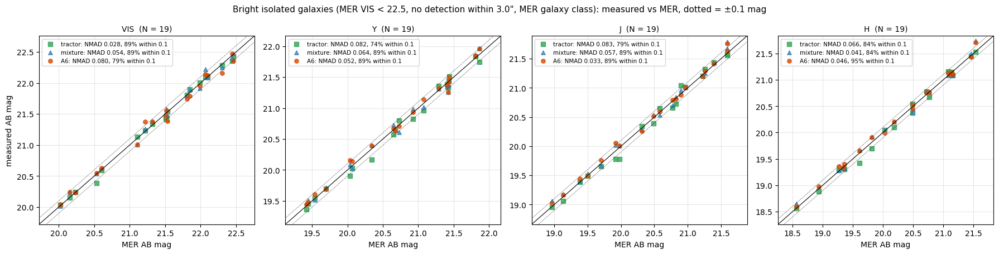

In [12]:
df = R.real_table(); print(len(df), 'source-bands with all methods')
fig = R.fig_bright_isolated(df); plt.show()

Over the full magnitude range the scatter against MER grows faint-ward for every method, as it must: at VIS 24–26 MER's own flux errors are ~0.1 mag. The panels below show method − MER against magnitude with the running median and 16–84 % band; the table after them separates each method's own scatter from MER's.

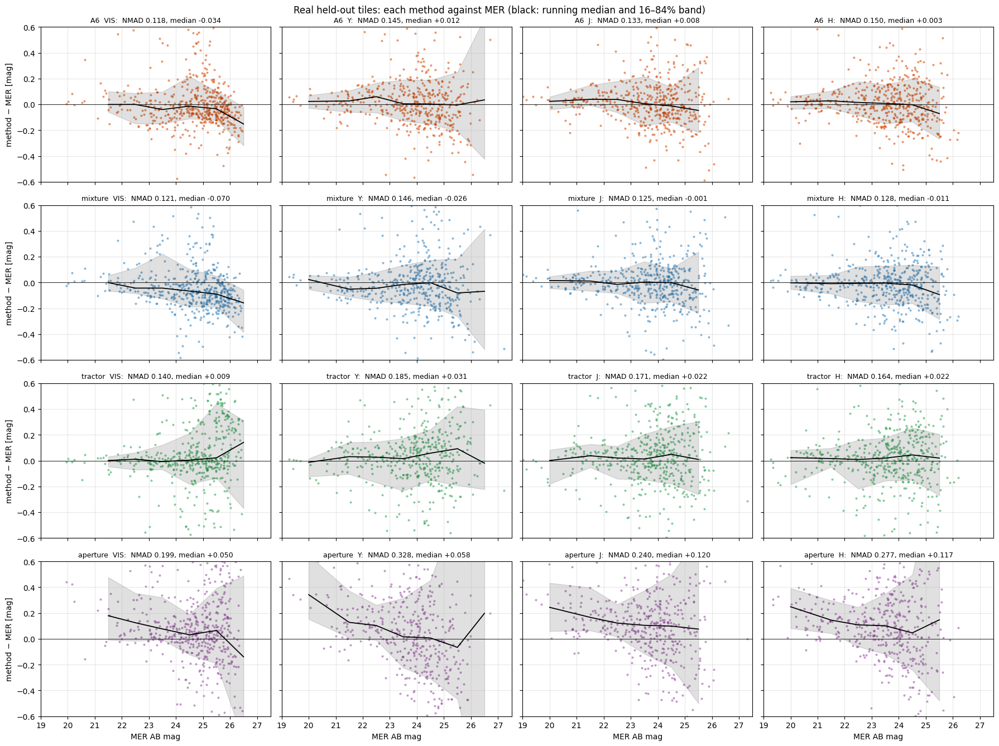

In [13]:
fig = R.fig_real_vs_mer(df); plt.show()

In [14]:
rows = []
for lo, hi in [(18, 21), (21, 22.5), (22.5, 24), (24, 25), (25, 26), (26, 27.5)]:
    s_ = df[df.vismag.between(lo, hi)]
    rows.append(dict(vis_mag=f'{lo}-{hi}', N=len(s_), **{f'{m} NMAD': round(R.nmad(s_[m] - s_.MER), 3) for m in ('A6', 'mixture', 'tractor', 'aperture')}, **{f'{m} within 0.1': f'{np.mean(np.abs(s_[m] - s_.MER) < .1):.0%}' for m in ('A6', 'mixture', 'tractor', 'aperture')}))
print('Agreement with MER by magnitude (all four Euclid bands)'); pd.DataFrame(rows).set_index('vis_mag')

Agreement with MER by magnitude (all four Euclid bands)


,N,A6 NMAD,mixture NMAD,tractor NMAD,aperture NMAD,A6 within 0.1,mixture within 0.1,tractor within 0.1,aperture within 0.1
vis_mag,,,,,,,,,
18-21,26,0.042,0.046,0.018,0.296,85%,85%,85%,0%
21-22.5,120,0.058,0.067,0.088,0.212,81%,82%,72%,39%
22.5-24,352,0.125,0.107,0.104,0.168,57%,62%,62%,36%
24-25,547,0.140,0.137,0.152,0.203,51%,52%,49%,34%
25-26,768,0.149,0.153,0.241,0.352,48%,46%,34%,26%
26-27.5,133,0.206,0.213,0.285,0.598,38%,27%,23%,14%


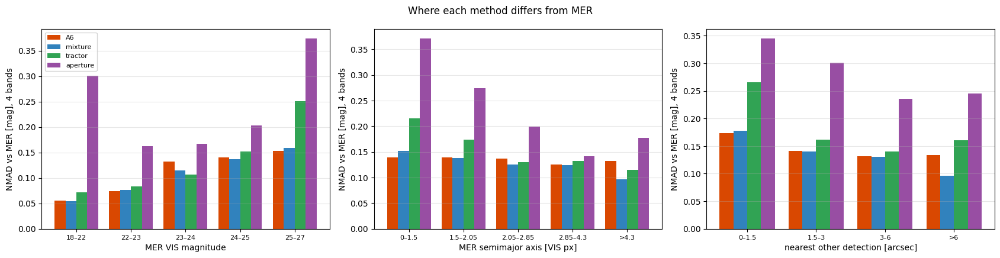

In [15]:
fig = R.fig_breakdown(df); plt.show()

In [16]:
rows = []
for label, sel in (('all sources, 4 bands', df.index == df.index), *[(b, df.index.get_level_values(1) == b) for b in R.EU], ('MER-clean galaxies, VIS 20-24', (df.clean & df.vismag.between(20, 24)).to_numpy())):
    d = df[sel]; pair, own = R.hat(d, ['A6', 'mixture', 'tractor', 'MER'])
    rows.append(dict(subset=label, N=len(d), **{f'{m} vs MER': round(pair[(m, 'MER')], 3) for m in ('A6', 'mixture', 'tractor')}, **{f'own {m}': round(v, 3) for m, v in own.items()}))
print('Four-cornered hat: the six pairwise NMADs (mag) solved for each method\'s own scatter. One head at a time (two heads share errors and both come out too low).')
pd.DataFrame(rows).set_index('subset')

Four-cornered hat: the six pairwise NMADs (mag) solved for each method's own scatter. One head at a time (two heads share errors and both come out too low).


,N,A6 vs MER,mixture vs MER,tractor vs MER,own A6,own mixture,own tractor,own MER
subset,,,,,,,,
"all sources, 4 bands",1949,0.140,0.132,0.168,0.080,0.080,0.148,0.101
euclid_VIS,503,0.118,0.121,0.140,0.091,0.092,0.160,0.045
euclid_Y,469,0.145,0.146,0.185,0.074,0.086,0.157,0.114
euclid_J,485,0.133,0.125,0.171,0.077,0.067,0.145,0.102
euclid_H,492,0.150,0.128,0.164,0.070,0.079,0.137,0.109
"MER-clean galaxies, VIS 20-24",370,0.087,0.081,0.078,0.057,0.072,0.089,0.037


## 6. Random held-out sources: data, model, residual
Eight sources spanning VIS 19–27 (seeded random draw). Lime circle: the measured source; cyan crosses: neighbours fitted jointly in the same solve. δ is the learned centroid correction applied; the table below gives each method's magnitudes.

These cutouts are the amortised head's fits (the validated inference path). The brightest galaxies show structured core residuals: their peak pixels reach 60–270σ, so a few-per-cent shape mismatch is a 10σ residual, concentrated inside 0.5″ (χ²/dof 74 in VIS and 552 in r for the first galaxy; ~1 beyond 2″). Model and data centroids agree to ≤ 0.03″, so these are not position errors; the enclosed flux within 1″ is 0.985–1.04 of the data's and the magnitudes agree with MER to 0.01–0.07 mag. These residuals are the current limit of the amortised shapes at the cores of bright galaxies, and the run in progress (A8: shape-fidelity term up-weighted for bright sources, five trained refinement passes) targets exactly them. Fitting them away at inference is not an option: see the next figure. The fourth row is a point source (MER point-like probability 0.94, unresolved; its core width equals the archive PSF stamp's to 1 %). Here the limit is the PSF model, not the shape network: fitting it with the PSF stamp itself, with sub-pixel position and point-source weight optimised, still leaves a core χ²/dof of ~17 (peak pixel 90σ, i.e. residuals of a few per cent of the peak), which is the level at which the nearest archive GRID stamp in a 2.1″ box differs from the local PSF. The methods then disagree at the 0.1–0.2 mag level on how much wing flux a point source has: A6 21.49, Tractor 21.36, mixture 21.32, per-scene optimised shapes 21.27, against MER's own PSF photometry 21.45 (its Sérsic value, 21.38, extrapolates wings for an unresolved object). A6 is in fact the closest to MER's point-source measurement. Point sources therefore need a better PSF model (a spatially varying effective PSF) before any photometer can do better on them.

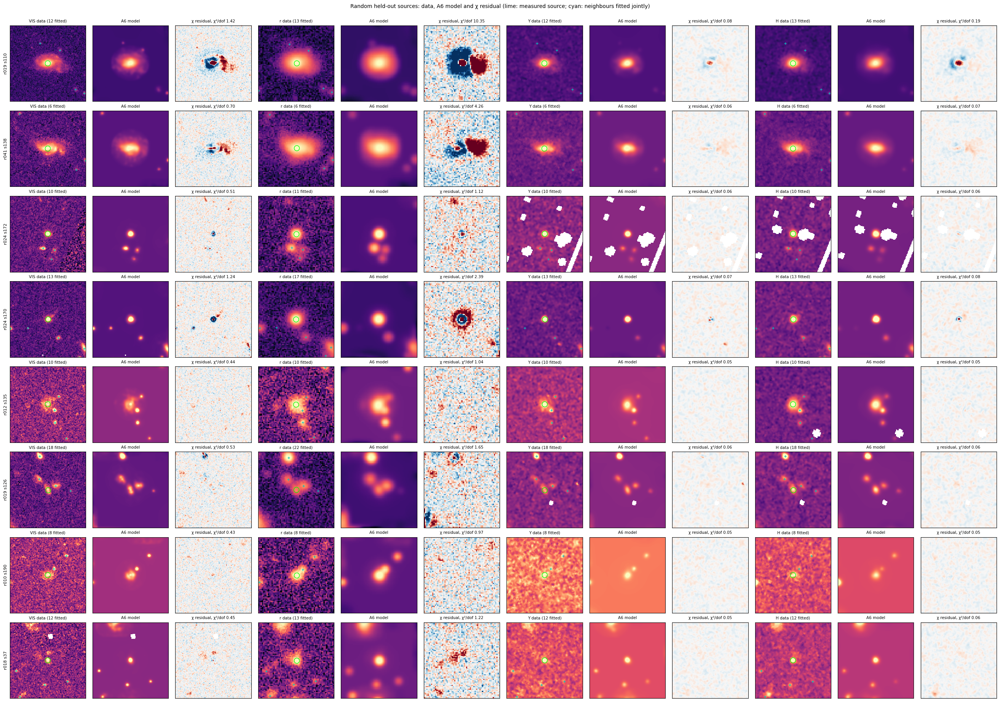

A6  mixture  tractor  aperture    MER
source              band                                          
region019_source110 VIS   19.95    19.92    19.93     20.39  19.94
                    Y     19.34    19.33    19.30     19.75  19.28
                    J     19.08    19.08    19.03     19.47  19.02
                    H     18.88    18.88    18.84     19.27  18.84
region041_source138 VIS   20.54    20.54    20.39     21.31  20.53
                    Y     20.16    20.09    19.90     20.84  20.04
                    J     20.05    20.02    19.78     20.73  19.92
                    H     19.91    19.91    19.69     20.63  19.81
region024_source172 VIS   22.39    22.33    22.44     22.41  22.33
                    Y     21.54    21.43    21.70     21.51  21.56
                    J     21.30    21.30    21.34     21.37  21.27
                    H     21.02    20.94    21.07     21.08  20.98
region024_source170 VIS   21.49    21.32    21.36     21.33  21.38
                    Y     21.05    21.02    21.24     21.04  21.13
                    J     21.00    20.98    21.13     21.02  21.02
                    H     21.10    20.95    21.14     21.07  21.08
region012_source135 VIS   23.01    23.17    22.93     23.60  23.08
                    Y     21.50    21.52    21.23     21.96  21.55
                    J     21.02    21.09    20.79     21.49  21.09
                    H     20.63    20.70    20.42     21.04  20.70
region019_source126 VIS   23.38    23.52    23.49     23.42  23.28
                    Y     22.65    22.58    22.65     22.60  22.53
                    J     22.37    22.35    22.37     22.35  22.26
                    H     22.29    22.27    22.28     22.27  22.14
region010_source190 VIS   23.67    23.76    23.59     23.88  23.59
                    Y     23.45    23.46    23.32     23.74  23.46
                    J     23.05    23.11    22.88     23.30  23.02
                    H     23.13    23.15    22.99     23.33  23.09
region018_source37  VIS   23.88    23.77    23.92     23.97  23.95
                    Y     23.32    23.18    23.37     23.34  23.48
                    J     22.78    22.51    22.80     22.81  22.93
                    H     22.95    22.69    22.95     23.08  23.06

In [17]:
fig = R.fig_examples(); plt.show()
R.example_table()

**Why not simply fit the pixels at inference?** Optimising the same bounded shape parameters against each scene's χ² removes the bright-source residuals completely (below: VIS core χ²/dof 74 → 1.5, r 552 → 4) with the bright sources' own fluxes unchanged. But on injections with known truth (table in section 4) it degrades everything else: with every source free, close blends go from 2.11 to 6.79 and the faint-end bias from −12 % to +28 %; even restricted to sources above 10σ with a tether to the network's prediction, close blends go to 3.04 and faint neighbours to −28 %. A bright source fitted to its pixels absorbs its neighbours' light: the residual reaches zero while the split between sources goes wrong, which is exactly the χ²-only failure the truth-supervised training was built to avoid. Shapes have to be learned under truth supervision, not fitted per scene.

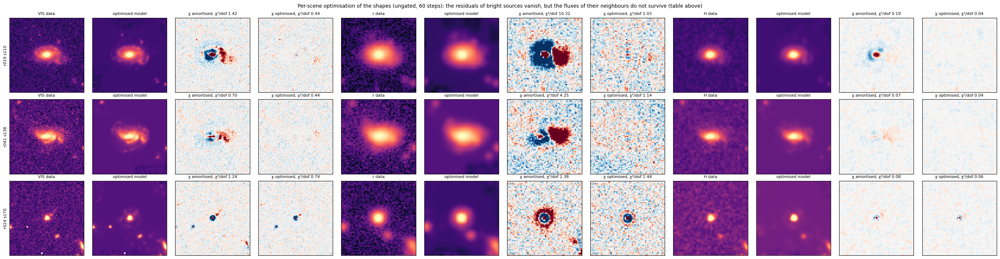

In [18]:
fig = R.fig_tto_examples(); plt.show()

## 6b. Fixing the bright cores from the training side: A7 and A8
Per-scene optimisation (above) shows the shape family *can* represent the bright cores; the amortised head just does not predict them well enough. Two fine-tunes of A6_v4 (same data, 5 passes over 100k `train_v4` scenes, same v4 loss) attack this in training rather than at inference:
- **A7_v4**: a learned point-source template per source (a PSF-shaped component with a learned weight), aimed at the stars, where the archive GRID PSF stamp leaves few-per-cent core residuals even when fitted directly. Its selection metric never improved on the initial checkpoint, so its *last* checkpoint (fully trained) is shown.
- **A8_v4**: the per-source model-image term of the loss is up-weighted by true S/N (up to 10×, `--template-snr 10 --template-wmax 10`), so bright sources' *shapes* count in the loss as much as their fluxes. Checkpoint selected on `val_v3` as usual (88k scenes).

The figure shows the same three bright held-out sources as above with each head's residual; the core χ²/dof is measured within 0.5″ of the centre. Every number below was produced on CPU with the saved checkpoints (`diag_*_{A7_v4_last,A8_v4}.csv`, `core_examples_*.npz`).

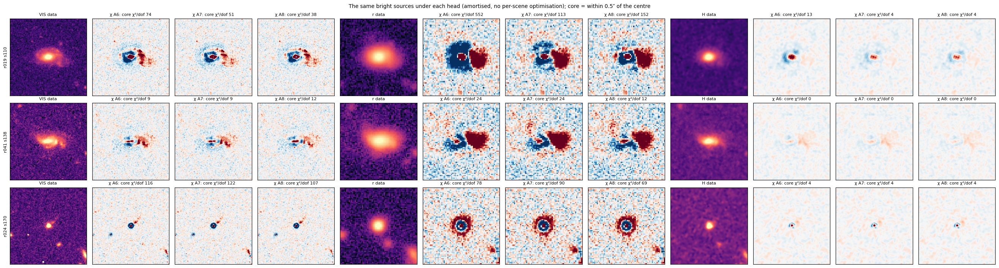

core χ²/dof (r < 0.5") and enclosed model/data flux within 1" for the three examples


chi2_core                 enclosed            
head                                  A6      A7      A8       A6    A7    A8
name                band                                                     
region019_source110 euclid_H       12.74    3.89    3.51     0.89  0.95  0.96
                    euclid_VIS     73.67   50.92   37.80     0.99  0.99  1.00
                    rubin_r       551.67  113.42  152.22     0.98  1.00  1.01
region024_source170 euclid_H        3.91    4.03    3.76     0.96  0.96  0.96
                    euclid_VIS    115.89  121.62  107.45     0.86  0.85  0.86
                    rubin_r        77.51   90.37   69.15     1.02  1.02  1.02
region041_source138 euclid_H        0.34    0.32    0.22     1.04  1.03  1.03
                    euclid_VIS      9.49    9.04   11.76     1.04  1.02  1.00
                    rubin_r        24.11   24.32   12.33     1.03  1.04  1.01

In [19]:
fig = R.fig_head_examples(); plt.show()
core = pd.concat([pd.read_csv(D / f'diag_core_{t}.csv').assign(head=l) for t, l in (('A6_v4', 'A6'), ('A7_v4_last', 'A7'), ('A8_v4', 'A8'))])
print('core χ²/dof (r < 0.5") and enclosed model/data flux within 1" for the three examples')
core.pivot_table(index=['name', 'band'], columns='head', values=['chi2_core', 'enclosed']).round(2)

A8 does what it was trained for on the galaxies: the VIS core χ²/dof of the brightest example drops from 74 to 38 and the r-band one from 552 to 152 (A7, which only adds a point component, gets part of the same gain because its fine-tune also ran five passes). Neither changes the star (VIS core ~110 for all three): the point template did not help, which agrees with the earlier finding that even fitting the archive PSF stamp itself leaves that residual. The remaining limit for point sources is the PSF model, not the head.

What matters is whether the better shapes buy better fluxes. Injections with known truth first (same `summary` as section 4, `val_v3`, exact positions), then the real tiles.

In [20]:
heads = {'A6': 'A6_v4', 'A7 (last)': 'A7_v4_last', 'A8': 'A8_v4'}
inj = {}
for who, run in heads.items():
    t = R.injection_table('val_v3', run=run, who=who); inj.setdefault('oracle', t['oracle']); inj.setdefault('mixture', t['mixture']); inj[who] = t[who]
print('val_v3, exact positions (median |Δ|/σ; bias = median fractional error)'); display(summary(inj))
rows = []
for who, run in heads.items():
    d = R.real_table(run=run, who=who); r = dict(head=who)
    for b in R.EU: g = d.xs(b, level='band'); r[f'{R.SHORT[b]} vs MER'] = R.nmad(g[who] - g.MER)
    r['4-band vs MER'] = np.mean([r[f'{R.SHORT[b]} vs MER'] for b in R.EU])
    br = d[d.clean & (d.vismag < 22.5) & (d.near > 3)]; r['bright isolated vs MER'] = R.nmad(br[who] - br.MER)
    cl = d[d.near < 1.5]; r['close pairs (<1.5") vs MER'] = R.nmad(cl[who] - cl.MER)
    big = d[d['size'] > d['size'].quantile(.9)]; r['largest 10% vs MER'] = R.nmad(big[who] - big.MER)
    _, own = R.hat(d, [who, 'mixture', 'tractor', 'MER']); r['own scatter (4-way hat)'] = own[who]; r['mixture own'] = own['mixture']
    rows.append(r)
print('real held-out tiles, 504 sources × 4 Euclid bands (NMAD, mag); mixture vs MER 4-band = 0.130 on the same rows'); pd.DataFrame(rows).set_index('head').round(3)

val_v3, exact positions (median |Δ|/σ; bias = median fractional error)


,overall,isolated,"blend 0.7-2""","blend <0.7""",bright_snr30,bias_snr_lt3,bias_snr_3_10,frac_nmad_snr30
method,,,,,,,,
oracle,1.426,1.010,1.190,1.266,1.442,-0.168,-0.042,0.030
mixture,2.164,1.524,1.839,2.183,5.073,0.045,-0.043,0.103
A6,1.980,1.434,1.693,1.881,4.440,-0.132,-0.039,0.091
A7 (last),1.982,1.419,1.687,1.959,4.509,-0.128,-0.024,0.091
A8,1.967,1.391,1.683,1.905,4.310,-0.095,-0.026,0.089


real held-out tiles, 504 sources × 4 Euclid bands (NMAD, mag); mixture vs MER 4-band = 0.130 on the same rows


,VIS vs MER,Y vs MER,J vs MER,H vs MER,4-band vs MER,bright isolated vs MER,"close pairs (<1.5"") vs MER",largest 10% vs MER,own scatter (4-way hat),mixture own
head,,,,,,,,,,
A6,0.118,0.145,0.133,0.150,0.136,0.049,0.174,0.128,0.080,0.080
A7 (last),0.115,0.147,0.141,0.142,0.136,0.043,0.182,0.117,0.076,0.082
A8,0.120,0.152,0.141,0.143,0.139,0.051,0.193,0.127,0.081,0.081


**Reading.** On injections A8 is the best head at both ends: bright sources (S/N > 30) 4.31 vs 4.44 for A6, and the faint-end bias improves from −13 % to −10 %; overall and in close blends it is level with A6 (1.97 vs 1.98, 1.91 vs 1.88). On the real tiles, however, none of this shows: the four-band scatter against MER is 0.139 for A8 vs 0.136 for A6, the own scatter from the four-way hat is 0.081 for both, bright isolated galaxies agree with MER equally well (0.051 vs 0.049), and A8 is slightly *worse* on close pairs (0.193 vs 0.174) and no better on the largest galaxies. A7 is indistinguishable from A6 everywhere except a worse close-blend number on injections (1.96 vs 1.88).

So the up-weighted shape term buys better-looking models and a small injection gain without any gain against MER, and costs a little in real close pairs: the bright cores it now fits are structure (bars, clumps, dust lanes) that carries a few per cent of the flux at most, which is below MER's own 0.10 mag noise. A6_v4 stays the reference head of this report. The useful outcome is negative in a precise way: the remaining bright-end gap to the mixture on real data (largest galaxies, J band) is not caused by the core residuals.

## 7. Speed, and what is left to improve
- **Speed**: 0.33 s per measured source on one L40S (A6 fits ~14 sources jointly per 12″ scene, keeping the central one, 5 GB), vs 0.87 s per source per CPU core for the adapted Tractor. Tractor parallelises across cores; the head does not yet batch scenes or keep every fitted source per scene, so a tile-level mode would be roughly an order of magnitude cheaper per source. Claim "comparable or faster", not "much faster", until that exists.
- **Bias**: median fractional bias at S/N < 3 is about −13 % on injections (same as the mixture); the oracle itself is −5 % on blank sky and −20 % in real scenes because undetected light couples into any constant-background model. At S/N 3–10 the head is within ±5 %.
- **Bright end headroom**: for bright isolated injected galaxies A6 scatters 4–6 % while the noise floor is 1–3 %; against MER the mixture is still slightly better on the largest galaxies (MER semimajor axis > 0.43″) and in J. This is the main place to gain.
- **MER**: its own scatter (~0.10 mag) is the largest term in any head-vs-MER number; agreement with MER partly rewards models whose errors correlate with MER's (smooth parametric wings).
- **Rubin bands**: the r-band residuals of the two brightest example galaxies show a dipole, i.e. the Rubin model sits displaced from the Rubin data. This is not a registration problem (flux-weighted centroids of the 37 brightest held-out sources agree with the catalogue positions to 0.016″ in every band, with no net Rubin–Euclid shift) but a shape/PSF mismatch: the Rubin PSF is a calibrated Gaussian approximation and the centroid correction is shared across bands. Rubin fluxes have no external reference in this notebook (MER is Euclid-only) and are unvalidated.
- **More refinement passes, trained in**: the pass test above suggests fine-tuning with 4–5 passes should help the bright end; untrained extra passes at inference do not.
- **Stars / point sources**: the archive GRID PSF stamps (nearest sample, 2.1″ box) leave few-per-cent core residuals on bright point sources even when fitted with the PSF itself, and the wing treatment moves point-source fluxes by 0.1–0.2 mag between methods (section 6). A learned point-source template (A7_v4, section 6b) did not reduce the star residuals at all, so the limit is the PSF model itself; the project's effective-PSF work (`models/psf/`) is the natural next step.
- **Bright-galaxy cores**: the amortised shapes leave structured residuals at 60–270σ cores. Per-scene pixel fitting removes them but trades light between sources (section 4 table, section 6), so the fix has to come from training. A8_v4 (shape-fidelity term up-weighted for bright sources, five trained passes; section 6b) halves those residuals and improves the bright and faint ends on injections, but gives nothing against MER on real tiles and slightly worsens close pairs. The core structure holds too little flux to matter at MER's noise level; the bright-end headroom above is elsewhere (wings and the largest galaxies).
- **Not yet done**: the frozen tests on A6_v4 (128 blends, empirical pilot, 28 test tiles vs Tractor/MER); a batched tile-level inference mode.